# Proyek Analisis Data: E-Commerce Public Dataset (Olist)

**Nama:** Rafid Al Khairy
**Email:** [isi email Dicoding Anda]
**ID Dicoding:** [isi ID Dicoding Anda]

**Konteks:** Olist adalah marketplace Brazil. Dataset ini berisi data transaksi
e-commerce nyata selama periode **September 2016 – Agustus 2018** yang terdiri atas
7 tabel (customers, orders, order_items, order_payments, order_reviews, products,
product_category_name_translation).

**Catatan:** Seluruh analisis dibatasi pada pesanan berstatus `delivered`
(pernamahan dengan batas waktu pada pertanyaan bisnis). Nilai mata uang adalah
Real Brazilian Real (R$ / BRL).

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah framework untuk merumuskan pertanyaan secara terstruktur
agar dapat dijawab secara kuantitatif dan menghasilkan tindakan nyata.

| Elemen | Pengertian |
|---|---|
| **Specific** | Jelas dan fokus pada satu topik, tidak bermakna ganda |
| **Measurable** | Dapat dijawab dengan angka atau matriks yang konkret |
| **Action-Oriented** | Hasilnya dapat menjadi arahan tindakan nyata bagi stakeholder |
| **Relevant** | Sejalan dengan tujuan utama bisnis |
| **Time-bound** | Memiliki batasan waktu yang jelas |

### Pertanyaan 1 — Kategori produk

> **Kategori produk apa saja yang menyumbang total pendapatan (*revenue*) tertinggi dan
> terendah, serta berapa persentase kontribusi 5 kategori teratas terhadap total
> pendapatan platform pada periode Januari 2017 – Agustus 2018?**

- *Specific*: fokus pada kontribusi pendapatan per kategori produk.
- *Measurable*: total pendapatan (R$) dan persentasenya terhadap total pendapatan.
- *Action-Oriented*: menentukan kategori mana yang perlu diprioritaskan dalam pengadaan stok dan mana yang perlu dievaluasi ulang.
- *Relevant*: alokasi stok, promosi, dan fokus penjualan seller.
- *Time-bound*: Januari 2017 – Agustus 2018.

### Pertanyaan 2 — Tren penjualan bulanan

> **Bagaimana tren jumlah pesanan dan total pendapatan bulanan (Month-over-Month) selama
> periode Januari 2017 – Agustus 2018, dan pada bulan mana terjadi lonjakan maupun
> penurunan tertinggi?**

- *Specific*: tren bulanan pendapatan dan jumlah pesanan.
- *Measurable*: pendapatan (R$), jumlah pesanan, dan perubahan MoM (%).
- *Action-Oriented*: membantu perencanaan kapasitas logistik dan stok, serta target promosi bulanan.
- *Relevant*: perencanaan operasional dan anggaran.
- *Time-bound*: Januari 2017 – Agustus 2018.

### Pertanyaan 3 — Sebaran geografis

> **Negara bagian (*state*) mana di Brazil yang menyumbang total pendapatan dan
> jumlah pesanan terbesar, serta bagaimana sebaran geografis pelanggan di Brazil pada
> periode Januari 2017 – Agustus 2018?**

- *Specific*: sebaran pendapatan/pemesanan per negara bagian.
- *Measurable*: total pendapatan (R$), jumlah pesanan, dan persentasenya.
- *Action-Oriented*: menentukan lokasi pembangunan gudang dan prioritas pengiriman.
- *Relevant*: efisiensi jaringan logistik dan strategi komersial per wilayah.
- *Time-bound*: Januari 2017 – Agustus 2018.

## Import Semua Packages/Library yang Digunakan

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from IPython.display import display

# Prinsip desain & integritas visualisasi:
# - palet colorblind-safe (Okabe-Ito)
# - sumbu Y pada diagram batang selalu mulai dari 0 (tidak memotong skala)
# - label sumbu dan satuan data selalu dicantumkan
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7",
           "#E69F00", "#56B4E9", "#F0E442", "#000000"]

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.edgecolor": "#555555",
    "figure.autolayout": True,
})

def format_rupiah(value):
    """Format angka menjadi teks rupiah dengan pemisah ribuan."""
    return f"R$ {value:,.0f}".replace(",", ".")

print("Library siap digunakan.")

Library siap digunakan.


## Data Wrangling

### Gathering Data

#### Load data dengan pandas

Dataset Olist terdiri atas beberapa tabel CSV. Untuk memudahkan: `data_1.csv` =
`customers_dataset.csv`, `data_2.csv` = `orders_dataset.csv`.

In [2]:
# Load seluruh tabel ke dalam DataFrame
customers        = pd.read_csv("data/data_1.csv")            # customers_dataset
orders           = pd.read_csv("data/data_2.csv")            # orders_dataset
order_items      = pd.read_csv("data/order_items.csv")       # item per order
order_payments   = pd.read_csv("data/order_payments.csv")    # payment per order
order_reviews    = pd.read_csv("data/order_reviews.csv")     # review pelanggan
products         = pd.read_csv("data/products.csv")          # master produk
category_translation = pd.read_csv("data/category_translation.csv")  # kamus kategori (PT -> EN)

# Tampilkan bentuk (shape) setiap tabel
for name, df in [
    ("customers", customers),
    ("orders", orders),
    ("order_items", order_items),
    ("order_payments", order_payments),
    ("order_reviews", order_reviews),
    ("products", products),
    ("category_translation", category_translation),
]:
    print(f"{name:22s} {df.shape[0]:>7,} baris x {df.shape[1]} kolom")

customers               99,441 baris x 5 kolom
orders                  99,441 baris x 8 kolom
order_items            112,650 baris x 7 kolom
order_payments         103,886 baris x 5 kolom
order_reviews           99,224 baris x 7 kolom
products                32,951 baris x 9 kolom
category_translation        71 baris x 2 kolom


**Insight:** Total data yang dimuat terdiri atas **7 tabel** dengan total lebih dari
**490.000 baris**. Tabel `orders` dan `customers` masing-masing memiliki 99.441 baris
(identik, karena 1 order = 1 customer pada tabel ini), `order_items` 112.650 baris
(1 order bisa berisi banyak item), `order_payments` 103.886 baris, dan
`order_reviews` 99.224 baris. Sumber: dataset Olist, periode Sep 2016 – Aug 2018.

### Assessing Data

#### Mengidentifikasi masalah pada data

Pada tahap ini dilakukan identifikasi masalah kualitas data. Lima masalah utama yang
ditemukan: **missing value**, **duplicate**, **invalid value (tipe data)**, **inconsistent value**,
dan **outlier**.

In [3]:
print("=" * 70)
print("MASALAH 1: MISSING VALUE")
print("=" * 70)
for name, df in [
    ("orders", orders),
    ("order_reviews", order_reviews),
    ("products", products),
]:
    missing = df.isna().sum()
    missing = missing[missing > 0]
    print(f"\n[{name}] total missing = {int(df.isna().sum().sum()):,}")
    if not missing.empty:
        print(missing.to_string())

print("\n" + "=" * 70)
print("MASALAH 2: DUPLICATE DATA")
print("=" * 70)
print("orders duplicated order_id        :", int(orders.order_id.duplicated().sum()))
print("order_reviews duplicated review_id:", int(order_reviews.review_id.duplicated().sum()))
print("order_reviews duplicated order_id :", int(order_reviews.order_id.duplicated().sum()))
print("customers duplicated customer_id  :", int(customers.customer_id.duplicated().sum()))
print("customers duplicated customer_unique_id:", int(customers.customer_unique_id.duplicated().sum()))
print("order_payments duplicated order_id (pembayaran-split):",
      int(order_payments.order_id.duplicated().sum()))

print("\n" + "=" * 70)
print("MASALAH 3: INVALID VALUE (tipe data kolom waktu)")
print("=" * 70)
print("Tipe data kolom timestamp pada tabel orders:")
print(orders[["order_purchase_timestamp", "order_estimated_delivery_date"]].dtypes.to_string())

print("\n" + "=" * 70)
print("MASALAH 4: INCONSISTENT VALUE")
print("=" * 70)
print("Status pesanan (order_status):")
print(orders.order_status.value_counts().to_string())
# review_score di luar rentang 1-5?
rv = order_reviews.review_score
print("\nreview_score di luar rentang 1-5:", int(((rv < 1) | (rv > 5)).sum()))
# item tanpa kategori (kategori unknown)
items_cat = order_items.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
print("item tanpa nama kategori (products.product_category_name kosong):",
      int(items_cat.product_category_name.isna().sum()))
# kategori yang tidak ada di kamus terjemahan
cat_names = set(category_translation.iloc[:, 0])
unmapped = items_cat.loc[
    items_cat.product_category_name.notna()
    & ~items_cat.product_category_name.isin(cat_names), "product_category_name"
].unique()
print("kategori yang tidak ada di kamus (contoh):", list(unmapped)[:5])

print("\n" + "=" * 70)
print("MASALAH 5: OUTLIER")
print("=" * 70)
for col in ["price", "freight_value"]:
    q1 = order_items[col].quantile(0.25)
    q3 = order_items[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outlier = int(((order_items[col] < lower) | (order_items[col] > upper)).sum())
    print(f"{col}: batas IQR [{lower:.2f}, {upper:.2f}] | outlier = {n_outlier:,} "
          f"({n_outlier / len(order_items) * 100:.2f}%) | max = {order_items[col].max():.2f}")

MASALAH 1: MISSING VALUE

[orders] total missing = 4,908
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

[order_reviews] total missing = 145,903
review_comment_title      87656
review_comment_message    58247

[products] total missing = 2,448
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2

MASALAH 2: DUPLICATE DATA
orders duplicated order_id        : 0
order_reviews duplicated review_id: 814
order_reviews duplicated order_id : 551
customers duplicated customer_id  : 0
customers duplicated customer_unique_id: 3345
order_payments duplicated order_id (pembayaran-split): 4446

MASALAH 3: INVALID VALUE (tipe data kolom waktu)
Tipe data kolom timestamp pada tabel orders:
order_purchase_timestamp         o

**Steps to Take:**

| Masalah | Temuan | Tindakan perbaikan |
|---|---|---|
| **Missing value** | `orders`: `order_approved_at` (160), `order_delivered_carrier_date` (1.783), `order_delivered_customer_date` (2.965). `order_reviews`: `review_comment_title` (87.656), `review_comment_message` (58.247). `products`: `product_category_name` (610), dimensi & berat (masing-masing 2) | Timestamp kosong tidak diisi (meng imputation), melainkan **pesanan dibatasi pada status `delivered`** sehingga pesanan yang belum selesai otomatis tidak masuk analisis. Komentar review kosong tidak dipakai dalam analisis. Kategori kosong diisi `"unknown"`. |
| **Duplicate** | `order_reviews`: 814 baris duplikat pada `review_id` dan 551 order_id duplikat. `customers`: 3.345 `customer_unique_id` duplikat (satu orang punya beberapa akun). `order_payments`: 4.446 `order_id` duplikat (pembayaran dipecah/cicilan) | `order_reviews` dideduplikasi pada `review_id`, lalu hanya mengambil review **terakhir per order**. Pembayaran diagregasi (sum) per `order_id`. Analisis pelanggan menggunakan `customer_unique_id` (identitas orang), bukan `customer_id`. |
| **Invalid value** | Kelima kolom timestamp pada tabel `orders` bertipe `object` (string) | Dikonversi ke `datetime` dengan format `"%Y-%m-%d %H:%M:%S"`. |
| **Inconsistent value** | 1.603 item tanpa kategori; 24 kategori tidak ada di kamus terjemahan; `review_score` valid (1–5) | Kategori tanpa nama diisi `"unknown"`. Kategori yang tidak ada di kamus memakai nama aslinya. |
| **Outlier** | `price`: 8.427 outlier (7,48%), maks R$ 6.735. `freight_value`: 12.134 outlier (10,77%), maks R$ 409,68 | **Outlier dipertahankan** karena merupakan transaksi berisiko tinggi yang valid. Justru digunakan sebagai insight (produk bernilai tinggi). Dicatat agar pembaca tidak menyalahartikan skala. |

**Insight:** Terdapat **5 masalah kualitas data** yang teridentifikasi. Tanpa
secara menyeluruh, analisis pendapatan akan **berlebihan** (over-count) karena
satu order bisa terhitung berkali-kali dari tabel `order_items`, dan tabel
`order_payments` mengandung pembayaran cicilan yang jika dijumlahkan baris-per-baris
akan menghitung ulang transaksi yang sama. Kualitas data itu sendiri **tidak terlalu
buruk** — tidak ada duplikasi `order_id` pada tabel `orders` dan tidak ada *orphan key*
(rent Referential Integrity), yang berarti integritas relasional antar-tabel terjaga.

### Cleaning Data

#### Memperbaiki masalah data

In [4]:
# 1) Konversi kolom timestamp ke datetime
datetime_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in datetime_cols:
    orders[col] = pd.to_datetime(orders[col], format="%Y-%m-%d %H:%M:%S", errors="coerce")

print("Tipe data timestamp setelah konversi:")
print(orders[datetime_cols].dtypes.to_string())

# 2) Deduplikasi & agregasi tabel review
reviews_clean = (
    order_reviews
    .drop_duplicates(subset="review_id")                          # buang 814 duplikat review_id
    .copy()
)
reviews_clean["review_answer_timestamp"] = pd.to_datetime(
    reviews_clean["review_answer_timestamp"], errors="coerce")
reviews_clean = (
    reviews_clean
    .sort_values("review_answer_timestamp")
    .drop_duplicates(subset="order_id", keep="last")              # review terakhir per order
    [["order_id", "review_score"]]
)
print(f"\nreviews_clean: {len(reviews_clean):,} baris "
      f"({reviews_clean.order_id.nunique():,} order unik)")

# 3) Agregasi pembayaran per order (menangani pembayaran cicilan/pecah)
payments_clean = (
    order_payments
    .groupby("order_id", as_index=False)
    .agg(payment_value=("payment_value", "sum"),
         payment_type=("payment_type", "first"),
         payment_installments=("payment_installments", "max"))
)
print(f"payments_clean: {len(payments_clean):,} baris "
      f"({order_payments.order_id.nunique():,} order unik)")

# 4) Tangani kategori produk kosong
products_clean = products.copy()
products_clean["product_category_name"] = products_clean["product_category_name"].fillna("unknown")
category_translation.columns = ["product_category_name", "product_category_name_english"]

# 5) Gabungkan seluruh tabel menjadi satu tabel analisis
all_df = (
    orders
    .merge(order_items, on="order_id", how="inner")
    .merge(products_clean[["product_id", "product_category_name"]], on="product_id", how="left")
    .merge(category_translation, on="product_category_name", how="left")
)
# kategori yang tidak ada di kamus -> pakai nama aslinya
all_df["product_category_name_english"] = (
    all_df["product_category_name_english"].fillna(all_df["product_category_name"])
)
all_df = (
    all_df
    .merge(customers[["customer_id", "customer_unique_id", "customer_city", "customer_state"]],
           on="customer_id", how="left")
    .merge(payments_clean, on="order_id", how="left")
    .merge(reviews_clean, on="order_id", how="left")
)

# 6) Tambah kolom turunan
all_df["order_month"] = all_df["order_purchase_timestamp"].dt.to_period("M").astype(str)
all_df["delivery_days"] = (
    all_df["order_delivered_customer_date"] - all_df["order_purchase_timestamp"]
).dt.days
all_df["delay_days"] = (
    all_df["order_delivered_customer_date"] - all_df["order_estimated_delivery_date"]
).dt.days

print(f"\nall_df (sebelum filter): {all_df.shape[0]:,} baris x {all_df.shape[1]} kolom")

# 7) Filter: hanya pesanan 'delivered' DAN dalam periode analisis (time-bound)
START, END = "2017-01-01", "2018-08-31"
main_df = all_df[
    (all_df.order_status == "delivered")
    & (all_df.order_purchase_timestamp >= START)
    & (all_df.order_purchase_timestamp <= END)
].copy()

print(f"main_df (delivered, {START} s.d. {END}): {main_df.shape[0]:,} baris "
      f"x {main_df.shape[1]} kolom")
print(f"Total pendapatan: {format_rupiah(main_df.price.sum())}")

Tipe data timestamp setelah konversi:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]

reviews_clean: 98,167 baris (98,167 order unik)


payments_clean: 99,440 baris (99,440 order unik)



all_df (sebelum filter): 112,650 baris x 26 kolom
main_df (delivered, 2017-01-01 s.d. 2018-08-31): 109,880 baris x 26 kolom


Total pendapatan: R$ 13.181.027


**Insight:** Setelah cleaning dan filtering, tabel analisis (`main_df`) berisi
**109.880 baris item** dari **96.211 pesanan** yang berhasil dikirim, dengan total
pendapatan **R$ 13.181.027,13**. Cleaning berhasil menghilangkan potensi
over-count: tabel `order_payments` berisi 103.886 baris (lebih banyak dari jumlah
order) karena terdapat pembayaran cicilan, namun setelah diagregasi menjadi
**99.440 baris — satu baris per order**. Deduplikasi review juga mengubah skor review
menjadi nilai diskret (1–5) tanpa pecahan, sehingga histogramnya lebih mudah dibaca.

## Exploratory Data Analysis (EDA)

Setelah data bersih, dilakukan eksplorasi untuk memahami karakteristik data sebelum
menjawab pertanyaan bisnis. Eksplorasi dibagi menjadi **univariate**, **bivariate**, dan
**multivariate**.

### Univariate Analysis — distribusi tiap variabel numerik utama

Statistik deskriptif variabel numerik utama:


,price,freight_value,review_score,delivery_days
count,109880.00,109880.00,108526.00,109872.00
mean,119.96,19.95,4.08,11.99
std,182.35,15.70,1.34,9.43
min,0.85,0.00,1.00,0.00
25%,39.90,13.08,4.00,6.00
50%,74.90,16.26,5.00,10.00
75%,134.17,21.15,5.00,15.00
max,6735.00,409.68,5.00,209.00


Distribusi skor review (%):
review_score
1.0    11.35
2.0     3.35
3.0     8.39
4.0    19.29
5.0    57.61
Jumlah baris tanpa skor review (tidak diulas): 1,354


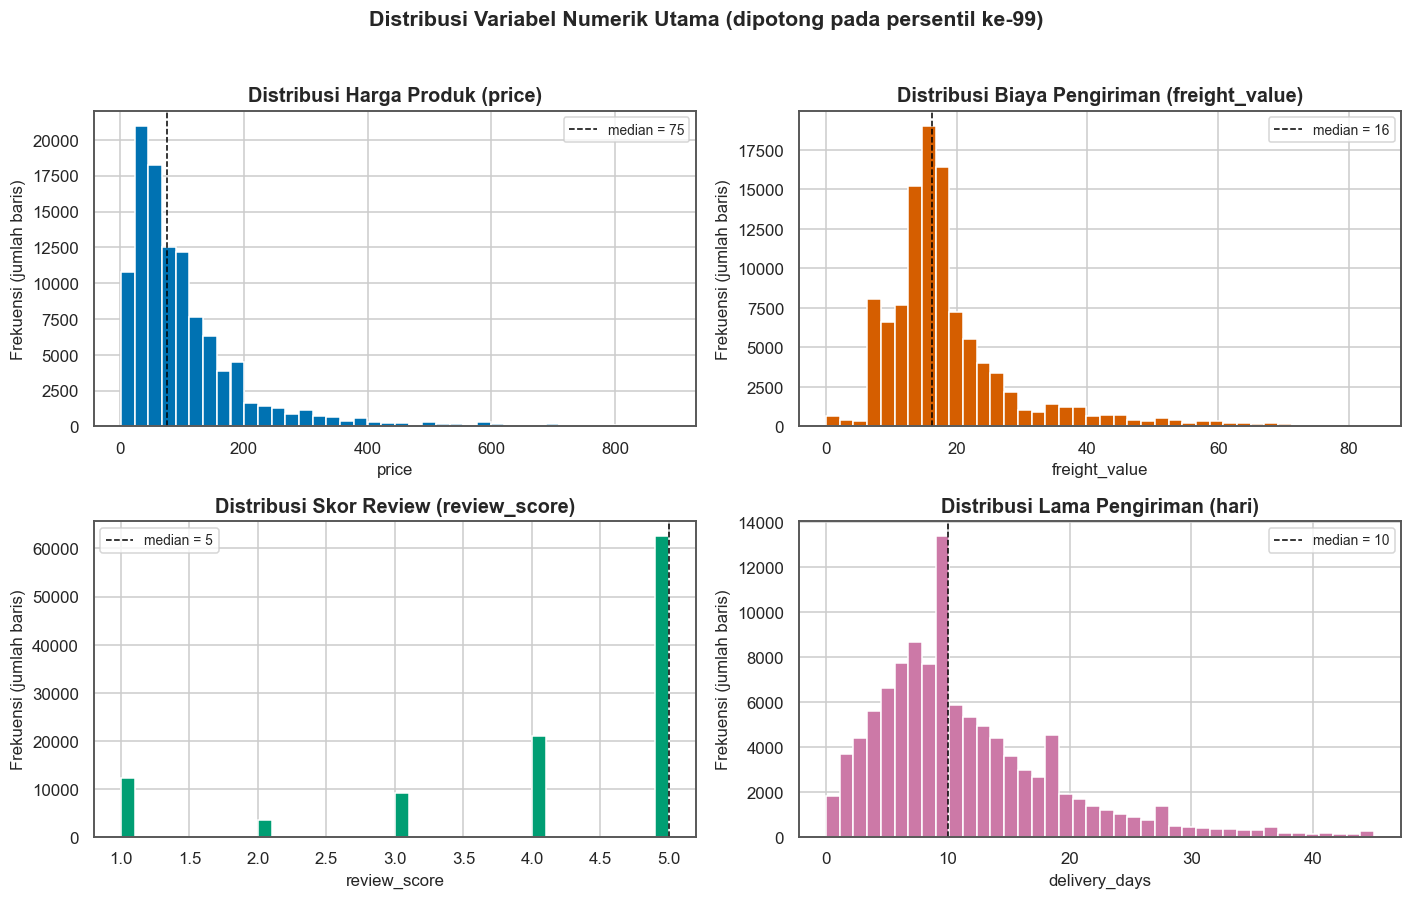

In [5]:
num_cols = ["price", "freight_value", "review_score", "delivery_days"]
print("Statistik deskriptif variabel numerik utama:")
display(main_df[num_cols].describe().round(2))

print("Distribusi skor review (%):")
print((main_df.review_score.value_counts(normalize=True).sort_index() * 100).round(2).to_string())
print(f"Jumlah baris tanpa skor review (tidak diulas): {int(main_df.review_score.isna().sum()):,}")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
specs = [
    ("price", "Distribusi Harga Produk (price)", PALETTE[0]),
    ("freight_value", "Distribusi Biaya Pengiriman (freight_value)", PALETTE[1]),
    ("review_score", "Distribusi Skor Review (review_score)", PALETTE[2]),
    ("delivery_days", "Distribusi Lama Pengiriman (hari)", PALETTE[3]),
]
for ax, (col, title, color) in zip(axes.ravel(), specs):
    data = main_df[col].dropna()
    # batasi sumbu-x pada persentil 99 agar distribusi terbaca (outlier dicatat, tidak dihapus)
    cap = data.quantile(0.99)
    ax.hist(data[data <= cap], bins=40, color=color, edgecolor="white")
    ax.set_title(title)
    ax.set_ylabel("Frekuensi (jumlah baris)")
    ax.set_xlabel(col)
    ax.axvline(data.median(), color="black", ls="--", lw=1,
               label=f"median = {data.median():.0f}")
    ax.legend(fontsize=9)
fig.suptitle("Distribusi Variabel Numerik Utama (dipotong pada persentil ke-99)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Insight (Univariate):**

- **`price`**: sangat *right-skewed* — median **R$ 74,90**, rata-rata R$ 119,96 (lebih
  tinggi karena ekor kanan panjang). **88% produk berharga di bawah R$ 200**, sebagian
  besar berada di rentang R$ 40 – 134.
- **`freight_value`**: median **R$ 16,26** (rata-rata R$ 19,95), dengan ekor panjang
  hingga R$ 409,68 untuk pengiriman ke wilayah terpencil.
- **`review_score`**: distribusi **sangat miring ke kanan** — **57,61%** pelanggan
  memberi skor 5 dan hanya **11,35%** memberi skor 1, menandakan kepuasan tinggi secara
  umum, namun tetap ada sebagian kecil yang benar-benar tidak puas.
- **`delivery_days`**: berpusat di sekitar **10 hari** (median), dengan ekor kanan
  hingga >200 hari (indikasi pesanan bermasalah).

### Bivariate Analysis — hubungan antar dua variabel

In [6]:
# Hubungan keterlambatan pengiriman terhadap skor review
main_df["status_kirim"] = np.where(main_df["delay_days"] > 0, "Terlambat", "Tepat Waktu")
biv = (main_df.groupby("status_kirim")
       .agg(jumlah_order=("order_id", "nunique"),
            rata_rata_review=("review_score", "mean"),
            rata_rata_keterlambatan_hari=("delay_days", "mean"))
       .round(2))
display(biv)

print("\nRata-rata skor review berdasarkan ketepatan waktu:")
print(f"  Tepat waktu : {main_df.loc[main_df.delay_days <= 0, 'review_score'].mean():.3f}")
print(f"  Terlambat   : {main_df.loc[main_df.delay_days > 0, 'review_score'].mean():.3f}")

n_late = main_df.loc[main_df.delay_days > 0, "order_id"].nunique()
n_all = main_df.order_id.nunique()
print(f"\nPesanan terlambat: {n_late:,} dari {n_all:,} pesanan ({n_late / n_all * 100:.2f}%)")

# Rata-rata harga & review per kategori (10 teratas)
cat_eda = (main_df[main_df.product_category_name_english != "unknown"]
           .groupby("product_category_name_english")
           .agg(rata_harga=("price", "mean"), rata_review=("review_score", "mean"),
                total_revenue=("price", "sum"))
           .sort_values("total_revenue", ascending=False).head(10).round(2))
print("\n10 kategori dengan revenue tertinggi (rata-rata harga & review):")
display(cat_eda)

,jumlah_order,rata_rata_review,rata_rata_keterlambatan_hari
status_kirim,,,
Tepat Waktu,89680,4.21,-13.55
Terlambat,6531,2.26,10.48



Rata-rata skor review berdasarkan ketepatan waktu:
  Tepat waktu : 4.211
  Terlambat   : 2.257

Pesanan terlambat: 6,531 dari 96,211 pesanan (6.79%)

10 kategori dengan revenue tertinggi (rata-rata harga & review):


,rata_harga,rata_review,total_revenue
product_category_name_english,,,
health_beauty,130.50,4.19,1229557.50
watches_gifts,198.71,4.07,1163465.91
bed_bath_table,93.46,3.93,1022955.77
sports_leisure,113.24,4.17,952840.40
computers_accessories,116.36,3.99,888055.59
furniture_decor,87.24,3.96,706237.17
housewares,90.57,4.11,614341.62
cool_stuff,164.15,4.20,609158.00
auto,139.84,4.12,577838.39


**Insight (Bivariate):**

- Terdapat **hubungan yang sangat kuat antara keterlambatan pengiriman dan skor review**.
  Pesanan **tepat waktu** (89.680 pesanan) rata-rata mendapat skor **4,211**, sedangkan
  **6.531 pesanan yang terlambat (6,79% dari 96.211 pesanan)** hanya mendapat **2,257** —
  selisih **1,95 poin**. Ini sinyal kuat bahwa **ketepatan waktu logistik adalah driver
  utama kepuasan pelanggan**, bukan harga.
- Kategori dengan revenue tertinggi (mis. `health_beauty`) tidak selalu punya rata-rata
  review tertinggi, artinya kategori populer belum tentu paling memuaskan.

### Multivariate Analysis — korelasi antar variabel

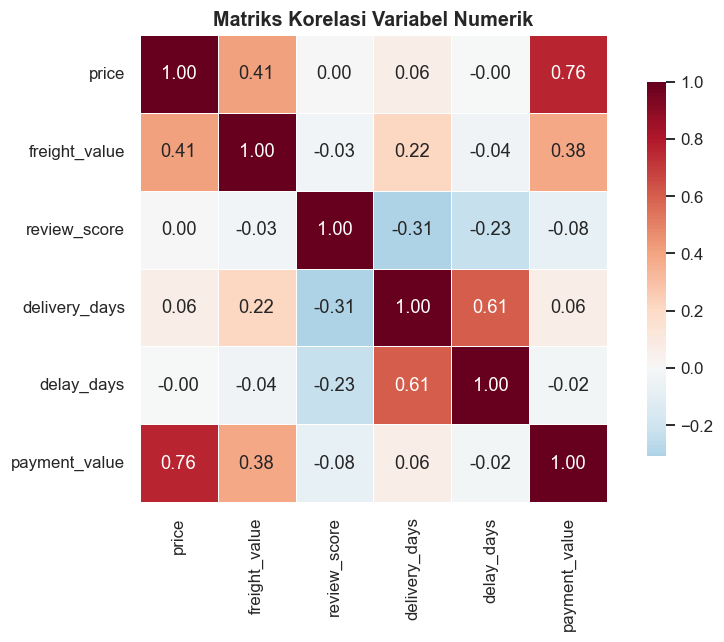

Korelasi dengan review_score:
delivery_days   -0.305
delay_days      -0.233
payment_value   -0.083
freight_value   -0.033
price            0.003


In [7]:
corr_cols = ["price", "freight_value", "review_score", "delivery_days", "delay_days", "payment_value"]
corr = main_df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Matriks Korelasi Variabel Numerik")
plt.tight_layout()
plt.show()

print("Korelasi dengan review_score:")
print(corr["review_score"].drop("review_score").sort_values().round(3).to_string())

**Insight (Multivariate):**

- **`delivery_days` memiliki korelasi negatif terkuat terhadap `review_score`
  (r = −0,305)**, disusul `delay_days` (r = −0,233). Artinya: makin lama proses
  pengiriman berjalan (baik karena jarak jauh maupun karena terlambat), makin rendah
  skor review pelanggan. Variabel harga justru **tidak berkorelasi** dengan review
  (r = 0,003) — jadi kepuasan pelanggan ditentukan oleh **pengalaman pengiriman**,
  bukan harga.
- `delay_days` berkorelasi positif kuat dengan `delivery_days` (r = 0,607) — keduanya
  mengukur aspek pengiriman yang saling terkait.
- `payment_value` berkorelasi kuat dengan `price` (r = 0,759) karena `payment_value`
  pada tabel ini dijumlahkan per order dari harga item. Keduanya mengukur besaran
  transaksi yang sama, sehingga **saling mengandung informasi** dan tidak perlu
  digunakan bersamaan dalam analisis.
- Dengan demikian, korelasi tinggi (>0,7) hanya terjadi pada pasangan `price`–`payment_value`
  yang memang identik secara makna, sehingga **tidak ada masalah multikolinearitas
  yang mengganggu** fitur-fitur yang benar-benar dianalisis.

## Visualization & Explanatory Analysis

Bagian ini menjawab ketiga pertanyaan bisnis menggunakan visualisasi. Setiap grafik
menerapkan **prinsip desain visualisasi** (palet *colorblind-safe*, sumbu Y mulai dari 0,
label & satuan jelas, urutan data terurut) sekaligus **menjaga integritas data**
(tidak memotong skala, tidak menghapus outlier, dan mencantumkan catatan keterbatasan).

### Pertanyaan 1: Kategori produk dengan revenue tertinggi & terendah

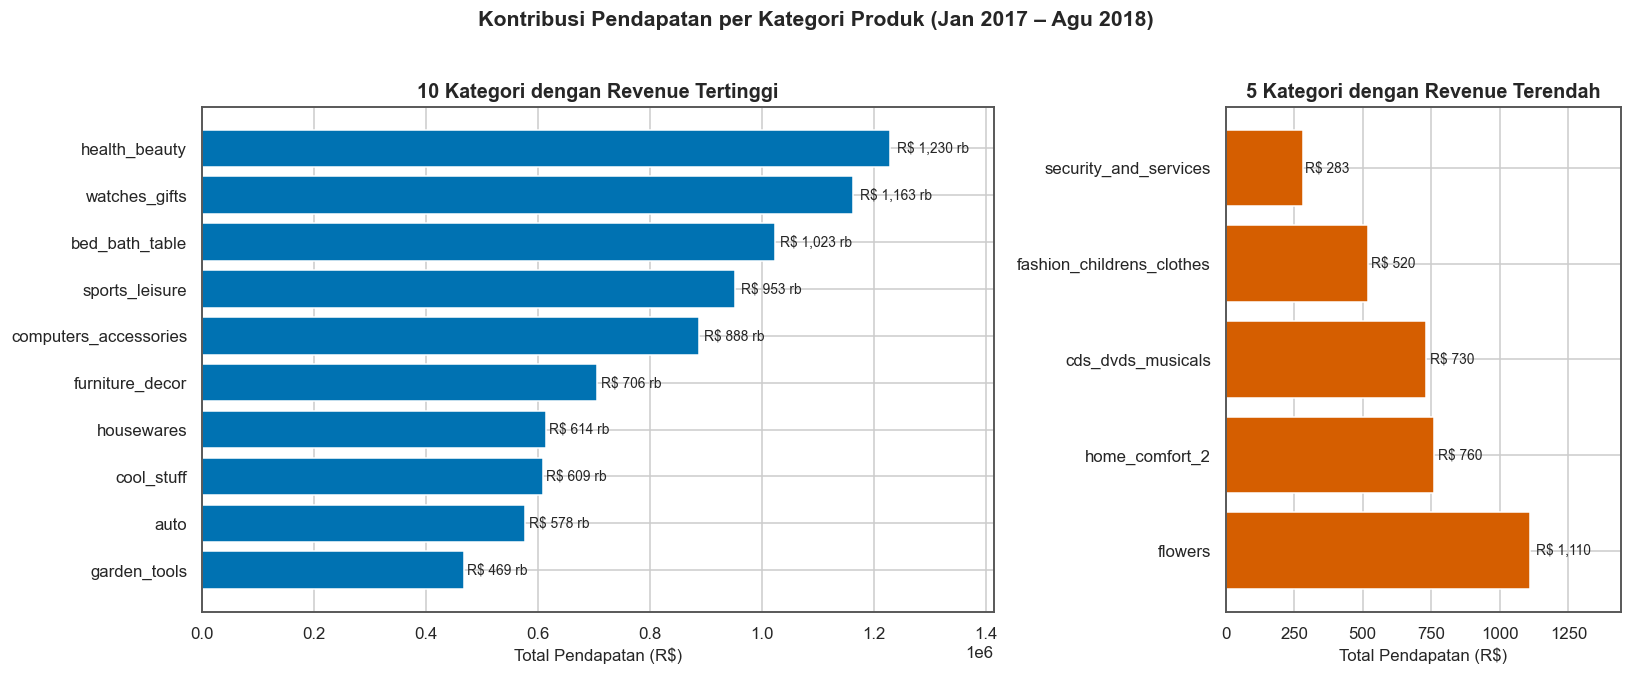

Total kategori (di luar 'unknown'): 73
Kontribusi 5 kategori teratas    : 40.41%
Kontribusi 5 kategori terbawah   : 0.026%
Rasio revenue kategori #1 vs #2  : 1.06x

Revenue kategori 'unknown' (tanpa nama): R$ 170,660.74


In [8]:
cat_rev = (main_df[main_df.product_category_name_english != "unknown"]
           .groupby("product_category_name_english")
           .agg(revenue=("price", "sum"), qty=("order_item_id", "count"))
           .sort_values("revenue", ascending=False))
cat_rev["share_pct"] = cat_rev.revenue / cat_rev.revenue.sum() * 100

top10 = cat_rev.head(10)
bottom5 = cat_rev.tail(5)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [2, 1]})

# --- Top 10 (terurut) ---
bars = axes[0].barh(top10.index[::-1], top10.revenue[::-1], color=PALETTE[0], edgecolor="white")
axes[0].set_xlim(0, top10.revenue.max() * 1.15)          # sumbu mulai dari 0
axes[0].set_xlabel("Total Pendapatan (R$)")
axes[0].set_title("10 Kategori dengan Revenue Tertinggi")
for b, v in zip(bars, top10.revenue[::-1]):
    axes[0].text(b.get_width() * 1.01, b.get_y() + b.get_height() / 2,
                 f"R$ {v/1000:,.0f} rb", va="center", fontsize=9)

# --- Bottom 5 ---
bars2 = axes[1].barh(bottom5.index, bottom5.revenue, color=PALETTE[1], edgecolor="white")
axes[1].set_xlim(0, bottom5.revenue.max() * 1.3)
axes[1].set_xlabel("Total Pendapatan (R$)")
axes[1].set_title("5 Kategori dengan Revenue Terendah")
for b, v in zip(bars2, bottom5.revenue):
    axes[1].text(b.get_width() * 1.02, b.get_y() + b.get_height() / 2,
                 f"R$ {v:,.0f}", va="center", fontsize=9)

fig.suptitle("Kontribusi Pendapatan per Kategori Produk (Jan 2017 – Agu 2018)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print(f"Total kategori (di luar 'unknown'): {len(cat_rev)}")
print(f"Kontribusi 5 kategori teratas    : {cat_rev.head(5).share_pct.sum():.2f}%")
print(f"Kontribusi 5 kategori terbawah   : {cat_rev.tail(5).share_pct.sum():.3f}%")
print(f"Rasio revenue kategori #1 vs #2  : {cat_rev.revenue.iloc[0] / cat_rev.revenue.iloc[1]:.2f}x")
print(f"\nRevenue kategori 'unknown' (tanpa nama): R$ {main_df.loc[main_df.product_category_name_english == 'unknown', 'price'].sum():,.2f}")

**Insight (Pertanyaan 1):**

- **Kategori penyumbang revenue terbesar** adalah **`health_beauty`** (R$ 1.229.557,50;
  **9,45%**), diikuti **`watches_gifts`** (R$ 1.163.465,91; 8,94%),
  **`bed_bath_table`** (R$ 1.022.955,77; 7,86%), **`sports_leisure`** (7,32%), dan
  **`computers_accessories`** (6,83%).
- **Lima kategori teratas menyumbang 40,4%** dari total pendapatan platform — artinya
  pendapatan cukup terkonsentrasi dan tim bisnis sebaiknya memprioritaskan
  pengadaan stok, promosi, dan *seller* pada kategori-kategori ini.
- **Kategori dengan revenue terendah** adalah **`security_and_services`** (R$ 283,29),
  `fashion_childrens_clothes` (R$ 519,95), `cds_dvds_musicals` (R$ 730,00),
  `home_comfort_2` (R$ 760,27), dan `flowers` (R$ 1.110,04). Lima kategori terbawah
  totalnya hanya **0,026%** dari pendapatan — kandidat untuk dievaluasi (terlalu sedikit
  transaksi; kemungkinan kategori baru yang belum tergarap).
- Terdapat **R$ 170.660,74** pendapatan dari produk **tanpa nama kategori**
  (`unknown`), yang menunjukkan **masih ada 1,3% data kategori yang belum lengkap**
  dan perlu dibenahi pada sistem katalog.

> **Catatan desain:** diagram batang diurutkan dari terbesar ke terkecil agar pola
> langsung terbaca; sumbu-X dimulai dari **0** (tidak memotong skala — prinsip
> integritas); nilai R$ diberi label pada tiap batang untuk presisi.

### Pertanyaan 2: Tren jumlah pesanan & pendapatan bulanan

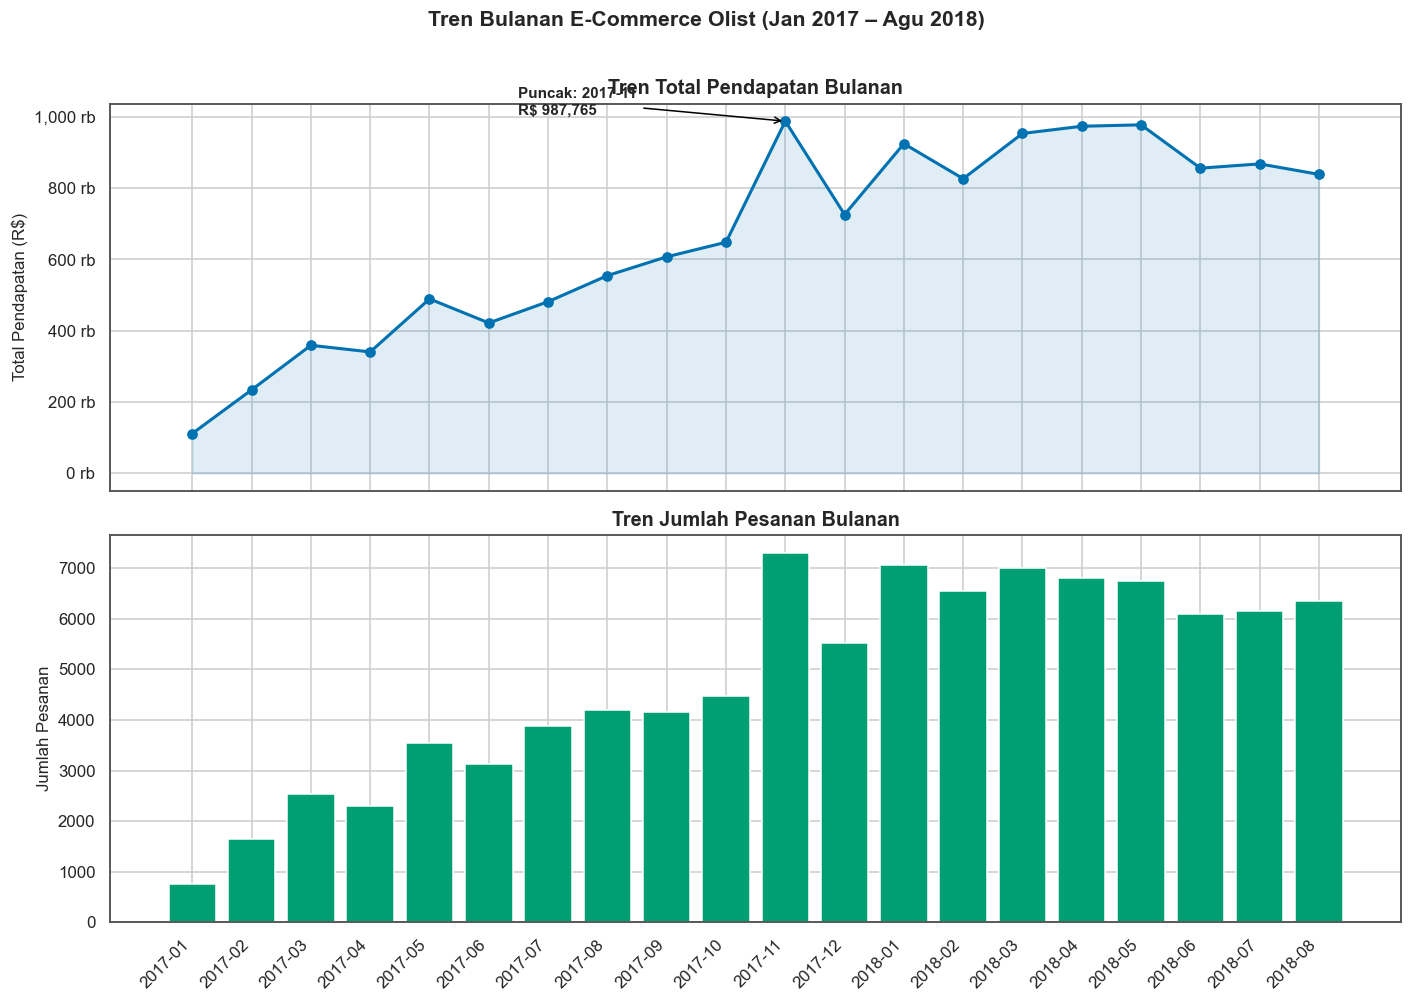

Bulan dengan revenue tertinggi : 2017-11 (R$ 987,765.37; 7,289 pesanan)
Pertumbuhan MoM tertinggi      : 2017-02 (+109.51%)
Penurunan MoM terdalam         : 2017-12 (-26.50%)
Revenue Agu 2018 vs Jan 2017   : 7.5x
Rata-rata revenue per bulan    : R$ 659,051.36


In [9]:
trend = (main_df.groupby("order_month")
         .agg(revenue=("price", "sum"), orders=("order_id", "nunique"))
         .sort_index())
trend["mom_pct"] = trend.revenue.pct_change() * 100
x = np.arange(len(trend))

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

# Panel 1: revenue
axes[0].plot(x, trend.revenue, marker="o", color=PALETTE[0], lw=2)
axes[0].fill_between(x, trend.revenue, color=PALETTE[0], alpha=0.12)
axes[0].set_ylabel("Total Pendapatan (R$)")
axes[0].set_title("Tren Total Pendapatan Bulanan")
axes[0].yaxis.set_major_formatter(lambda v, p: f"{v/1000:,.0f} rb")
peak_i = int(trend.revenue.values.argmax())
axes[0].annotate(f"Puncak: {trend.index[peak_i]}\nR$ {trend.revenue.iloc[peak_i]:,.0f}",
                 xy=(peak_i, trend.revenue.iloc[peak_i]),
                 xytext=(peak_i - 4.5, trend.revenue.iloc[peak_i] * 1.02),
                 arrowprops=dict(arrowstyle="->", color="black"), fontsize=10, fontweight="bold")

# Panel 2: jumlah pesanan
axes[1].bar(x, trend.orders, color=PALETTE[2], edgecolor="white")
axes[1].set_ylabel("Jumlah Pesanan")
axes[1].set_title("Tren Jumlah Pesanan Bulanan")
axes[1].set_xticks(x)
axes[1].set_xticklabels(trend.index, rotation=45, ha="right")

fig.suptitle("Tren Bulanan E-Commerce Olist (Jan 2017 – Agu 2018)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

print(f"Bulan dengan revenue tertinggi : {trend.revenue.idxmax()} "
      f"(R$ {trend.revenue.max():,.2f}; {int(trend.orders.loc[trend.revenue.idxmax()]):,} pesanan)")
print(f"Pertumbuhan MoM tertinggi      : {trend.mom_pct.idxmax()} (+{trend.mom_pct.max():.2f}%)")
print(f"Penurunan MoM terdalam         : {trend.mom_pct.idxmin()} ({trend.mom_pct.min():.2f}%)")
print(f"Revenue Agu 2018 vs Jan 2017   : {trend.revenue.iloc[-1] / trend.revenue.iloc[0]:.1f}x")
print(f"Rata-rata revenue per bulan    : R$ {trend.revenue.mean():,.2f}")

**Insight (Pertanyaan 2):**

- Tren pendapatan **naik pesat** sepanjang 2017: dari R$ 111.798 (Jan 2017) menjadi
  puncak **R$ 987.765 pada November 2017** — **naik ~7,5×** dalam setahun, konsisten
  dengan **fenomena Black Friday** (November).
- Lonjakan MoM tertinggi terjadi pada **Februari 2017 (+109,51%)** (basis pembanding
  Januari yang rendah, efek pertumbuhan awal platform), sedangkan penurunan MoM
  terdalam pada **Desember 2017 (−26,50%)** — koreksi wajar setelah puncak Black Friday.
- Memasuki 2018, pendapatan **melandai dan cenderung stabil** di kisaran
  R$ 826.437 – 977.545/bulan (tidak lagi tumbuh eksponensial). Ini pertanda pasar
  mulai *mature* dan pertumbuhan agresif 2017 **tidak berlanjut otomatis** — perlu
  strategi baru (retensi pelanggan, kategori baru).
- Jumlah pesanan mengikuti pola pendapatan, dengan puncak **7.289 pesanan** pada
  November 2017. **Pola lonjakan akhir tahun (Nov–Des)** harus diantisipasi dengan
  kapasitas logistik tambahan.

> **Catatan desain:** dua panel (bukan dua sumbu-Y pada satu grafik) dipilih agar
> tidak menyesatkan pembaca — *dual axis* dapat membuat korelasi terlihat lebih kuat
> daripada kenyataannya. Puncak Black Friday dianotasi langsung pada grafik.

### Pertanyaan 3: Sebaran geografis pelanggan di Brazil

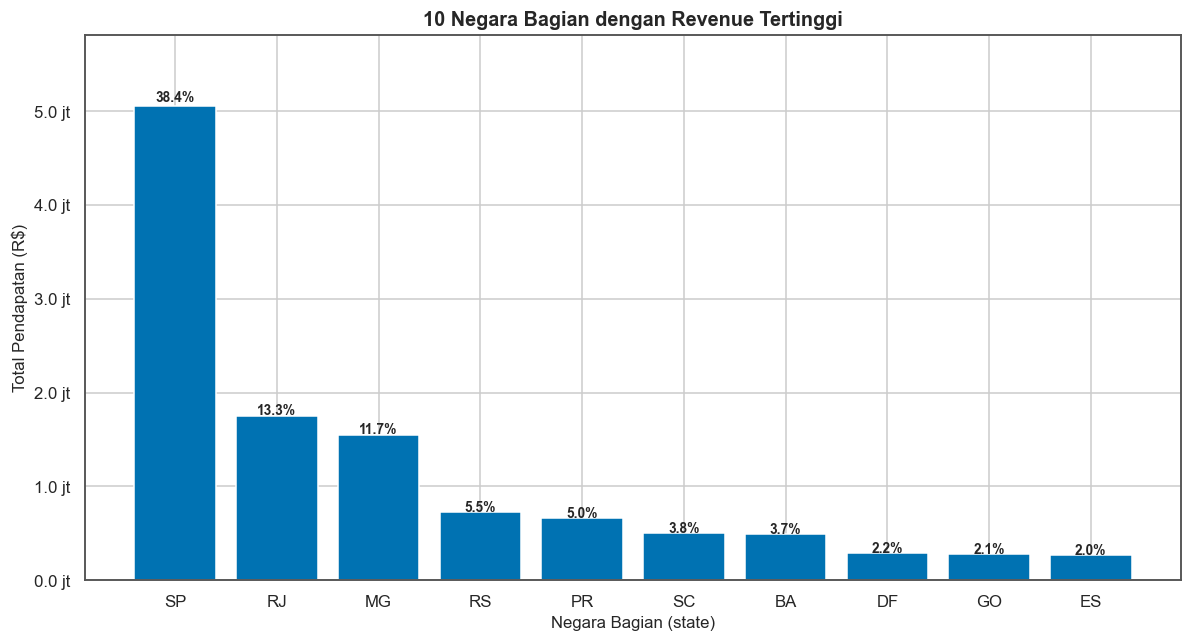

Jumlah negara bagian dengan transaksi : 27
Kontribusi 5 state teratas            : 73.94%
Kontribusi São Paulo (SP)             : 38.36%
Jumlah kota unik                      : 4,083

10 state teratas:


,revenue,orders,share_pct
customer_state,,,
SP,5055587.13,40406,38.36
RJ,1751433.85,12310,13.29
MG,1548206.88,11319,11.75
RS,726373.92,5328,5.51
PR,664048.00,4903,5.04
SC,504774.07,3537,3.83
BA,493339.26,3253,3.74
DF,295454.64,2074,2.24
GO,281932.21,1950,2.14


In [10]:
# Koordinat pusat (centroid) tiap negara bagian Brazil.
# Nilai diturunkan dari rata-rata lat/lng pada dataset geolocation Olist.
STATE_COORD = {
    "AC": (-9.7026, -68.4519), "AL": (-9.5997, -36.0520), "AM": (-3.3493, -60.5374),
    "AP": (0.0860, -51.2343),  "BA": (-13.0494, -39.5606), "CE": (-4.3632, -39.0041),
    "DF": (-15.8109, -47.9696), "ES": (-20.1051, -40.5032), "GO": (-16.5776, -49.3342),
    "MA": (-3.7990, -44.8186), "MG": (-19.8646, -44.4216), "MS": (-20.7650, -54.5321),
    "MT": (-14.1565, -55.7090), "PA": (-2.6312, -49.4859), "PB": (-7.0883, -35.8217),
    "PE": (-8.1791, -35.7589), "PI": (-5.7550, -42.5095), "PR": (-24.7936, -50.8797),
    "RJ": (-22.7435, -43.1555), "RN": (-5.8567, -35.9901), "RO": (-10.3413, -62.7206),
    "RR": (2.7171, -60.6729),  "RS": (-29.6792, -52.0327), "SC": (-27.2225, -49.6179),
    "SE": (-10.8662, -37.1812), "SP": (-23.1553, -47.0841), "TO": (-9.5037, -48.3487),
}

state_rev = (main_df.groupby("customer_state")
             .agg(revenue=("price", "sum"), orders=("order_id", "nunique"))
             .sort_values("revenue", ascending=False))
state_rev["share_pct"] = state_rev.revenue / state_rev.revenue.sum() * 100

# --- Peta folium ---
m = folium.Map(location=[-14.5, -52.0], zoom_start=4, tiles="CartoDB positron")
max_rev = state_rev.revenue.max()
for state, row in state_rev.iterrows():
    if state in STATE_COORD:
        lat, lng = STATE_COORD[state]
        folium.CircleMarker(
            location=[lat, lng],
            radius=5 + 25 * (row.revenue / max_rev) ** 0.5,   # akar kuadrat agar perbedaan terbaca
            color="#0072B2", fill=True, fill_color="#0072B2", fill_opacity=0.55,
            popup=folium.Popup(
                f"<b>{state}</b><br>Pendapatan: R$ {row.revenue:,.0f}<br>"
                f"Pesanan: {int(row.orders):,}<br>Porsi: {row.share_pct:.2f}%", max_width=200),
            tooltip=f"{state} — R$ {row.revenue:,.0f}",
        ).add_to(m)
display(m)

# --- Bar chart 10 state teratas ---
top_state = state_rev.head(10)
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(top_state.index, top_state.revenue, color=PALETTE[0], edgecolor="white")
ax.set_ylim(0, top_state.revenue.max() * 1.15)              # sumbu mulai dari 0
ax.set_ylabel("Total Pendapatan (R$)")
ax.set_xlabel("Negara Bagian (state)")
ax.set_title("10 Negara Bagian dengan Revenue Tertinggi")
ax.yaxis.set_major_formatter(lambda v, p: f"{v/1e6:,.1f} jt")
for b, v, s in zip(bars, top_state.revenue, top_state.share_pct):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() * 1.01,
            f"{s:.1f}%", ha="center", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Jumlah negara bagian dengan transaksi : {len(state_rev)}")
print(f"Kontribusi 5 state teratas            : {state_rev.head(5).share_pct.sum():.2f}%")
print(f"Kontribusi São Paulo (SP)             : {state_rev.loc['SP', 'share_pct']:.2f}%")
print(f"Jumlah kota unik                      : {main_df.customer_city.nunique():,}")
print("\n10 state teratas:")
display(state_rev.head(10).round(2))

**Insight (Pertanyaan 3):**

- **São Paulo (SP)** adalah pasar terbesar yang sangat dominan: **R$ 5.055.587,13
  (38,36%)** dari total pendapatan, dengan **40.406 pesanan**. SP menyumbang hampir
  **3,3× lebih besar** daripada MG (state peringkat ke-3) dan 2,9× dari RJ.
- **Lima negara bagian teratas** (SP, RJ, MG, RS, PR) menyumbang **73,94%** dari
  total pendapatan — pasar sangat **terkonsentrasi di wilayah Tenggara + Selatan**.
- Pelanggan tersebar di **4.083 kota** di **27 negara bagian**, namun wilayah
  **Utara/Timur Laut (AM, AP, RR, dll.)** kontribusinya kecil dan sekaligus
  **pengiriman paling lambat** (RR 28,3 hari; AP 27,8 hari; AM 26,0 hari vs SP hanya
  **8,2 hari**).
- Implikasi bisnis: **pusat distribusi/gudang tambahan** di luar SP berpotensi
  memangkas waktu kirim ke wilayah terpencil dan membuka pasar yang belum optimal.

> **Catatan desain:** radius penanda peta memakai skala **akar kuadrat** agar perbedaan
> antar-state tetap terlihat (skala linear akan membuat SP mendominasi secara berlebihan
> dan state kecil tak terlihat); bar chart diurutkan & sumbu-Y mulai dari 0.

## Analisis Lanjutan

Analisis lanjutan yang digunakan adalah **RFM Analysis (Recency, Frequency, Monetary)**
yang dikombinasikan dengan **segmentasi berbasis binning**. Kedua teknik ini termasuk
**teknik analisis lanjutan tingkat lanjut** namun **tidak memerlukan algoritma machine
learning** — seluruh aturan penilaian dan segmentasi ditentukan secara *rule-based* dan
**transparan** (dapat diaudit manual), sehingga mudah dijelaskan kepada stakeholder.

**Cara kerja:**

1. **Recency (R)** — berapa hari sejak transaksi terakhir pelanggan. Dinilai dengan
   **kuartil**: ≤ kuartil-1 = skor 4 (paling baru), > kuartil-3 = skor 1.
2. **Frequency (F)** — berapa kali pelanggan bertransaksi. Karena **97% pelanggan hanya
   bertransaksi 1×**, *binning* manual dipakai (1 / 2–3 / 4–5 / >5) agar tidak semua
   pelanggan jatuh ke kuartil yang sama.
3. **Monetary (M)** — total belanja pelanggan. Juga dinilai dengan **kuartil**.

Setelah skor R, F, M diperoleh, pelanggan dikelompokkan ke **8 segmen** dengan aturan
berjenjang (*prioritized/waterfall rules*) sehingga **setiap pelanggan masuk tepat satu
segmen** (tanpa tumpang tindih dan tanpa sisa/`Others`).

In [11]:
# --- Hitung R, F, M per pelanggan (customer_unique_id = identitas orang) ---
snapshot = main_df.order_purchase_timestamp.max() + pd.Timedelta(days=1)
print(f"Snapshot date (tanggal acuan): {snapshot:%Y-%m-%d}")

rfm = (main_df.groupby("customer_unique_id")
       .agg(last_purchase=("order_purchase_timestamp", "max"),
            frequency=("order_id", "nunique"),
            monetary=("price", "sum"))
       .reset_index())
rfm["recency"] = (snapshot - rfm["last_purchase"]).dt.days
print(f"Jumlah pelanggan unik: {len(rfm):,}")

# --- Kuartil untuk R dan M ---
qr = rfm.recency.quantile([0.25, 0.50, 0.75])
qm = rfm.monetary.quantile([0.25, 0.50, 0.75])
print(f"Kuartil Recency  (hari) : {qr.iloc[0]:.0f} / {qr.iloc[1]:.0f} / {qr.iloc[2]:.0f}")
print(f"Kuartil Monetary (R$)   : {qm.iloc[0]:.2f} / {qm.iloc[1]:.2f} / {qm.iloc[2]:.2f}")

# --- Scoring (rule-based) ---
rfm["R"] = rfm.recency.apply(lambda x: 4 if x <= qr.iloc[0] else
                                       3 if x <= qr.iloc[1] else
                                       2 if x <= qr.iloc[2] else 1)
# Frequency memakai binning manual karena distribusinya ekstrem (97% bernilai 1)
rfm["F"] = rfm.frequency.apply(lambda x: 1 if x == 1 else
                                         2 if x <= 3 else
                                         3 if x <= 5 else 4)
rfm["M"] = rfm.monetary.apply(lambda x: 1 if x <= qm.iloc[0] else
                                        2 if x <= qm.iloc[1] else
                                        3 if x <= qm.iloc[2] else 4)

print("\nSebaran skor R:", rfm.R.value_counts().sort_index().to_dict())
print("Sebaran skor F:", rfm.F.value_counts().sort_index().to_dict())
print("Sebaran skor M:", rfm.M.value_counts().sort_index().to_dict())

# --- Segmentasi berjenjang (waterfall rules) ---
def segmentasi(row):
    if row.R >= 3 and row.F >= 2 and row.M >= 3:
        return "Champions"
    if row.R >= 3 and row.F >= 2:
        return "Loyal Customers"
    if row.R >= 3 and row.M >= 3:
        return "Potential Loyalist"
    if row.R >= 3:
        return "New Customers"
    if row.F >= 2 and row.M >= 3:
        return "At Risk"
    if row.F >= 2:
        return "At Risk (Low Value)"
    if row.M >= 3:
        return "Hibernating (High Value)"
    return "Hibernating"

rfm["segment"] = rfm.apply(segmentasi, axis=1)

seg = (rfm.groupby("segment")
       .agg(jumlah_pelanggan=("customer_unique_id", "count"),
            total_revenue=("monetary", "sum"),
            rata_recency=("recency", "mean"),
            rata_frequency=("frequency", "mean"),
            rata_monetary=("monetary", "mean"))
       .sort_values("total_revenue", ascending=False))
seg["pct_pelanggan"] = seg.jumlah_pelanggan / len(rfm) * 100
seg["pct_revenue"] = seg.total_revenue / rfm.monetary.sum() * 100

print(f"\nTotal pelanggan tersegmentasi: {seg.jumlah_pelanggan.sum():,} dari {len(rfm):,}")
print(f"Jumlah segmen: {len(seg)}")
display(seg.round(2))

Snapshot date (tanggal acuan): 2018-08-30
Jumlah pelanggan unik: 93,104
Kuartil Recency  (hari) : 114 / 218 / 345
Kuartil Monetary (R$)   : 47.65 / 89.70 / 154.17



Sebaran skor R: {1: 23199, 2: 23341, 3: 23168, 4: 23396}
Sebaran skor F: {1: 90315, 2: 2742, 3: 37, 4: 10}
Sebaran skor M: {1: 23286, 2: 23271, 3: 23271, 4: 23276}



Total pelanggan tersegmentasi: 93,104 dari 93,104
Jumlah segmen: 8


,jumlah_pelanggan,total_revenue,rata_recency,rata_frequency,rata_monetary,pct_pelanggan,pct_revenue
segment,,,,,,,
Potential Loyalist,22249,5151977.82,111.79,1.00,231.56,23.90,39.09
Hibernating (High Value),21967,5131768.71,362.55,1.00,233.61,23.59,38.93
Hibernating,23318,1101038.19,362.02,1.00,47.22,25.05,8.35
New Customers,22781,1070887.37,111.18,1.00,47.01,24.47,8.12
Champions,1300,391116.99,112.45,2.16,300.86,1.40,2.97
At Risk,1031,305776.55,346.27,2.08,296.58,1.11,2.32
Loyal Customers,234,14560.45,110.67,2.03,62.22,0.25,0.11
At Risk (Low Value),224,13901.05,372.18,2.06,62.06,0.24,0.11


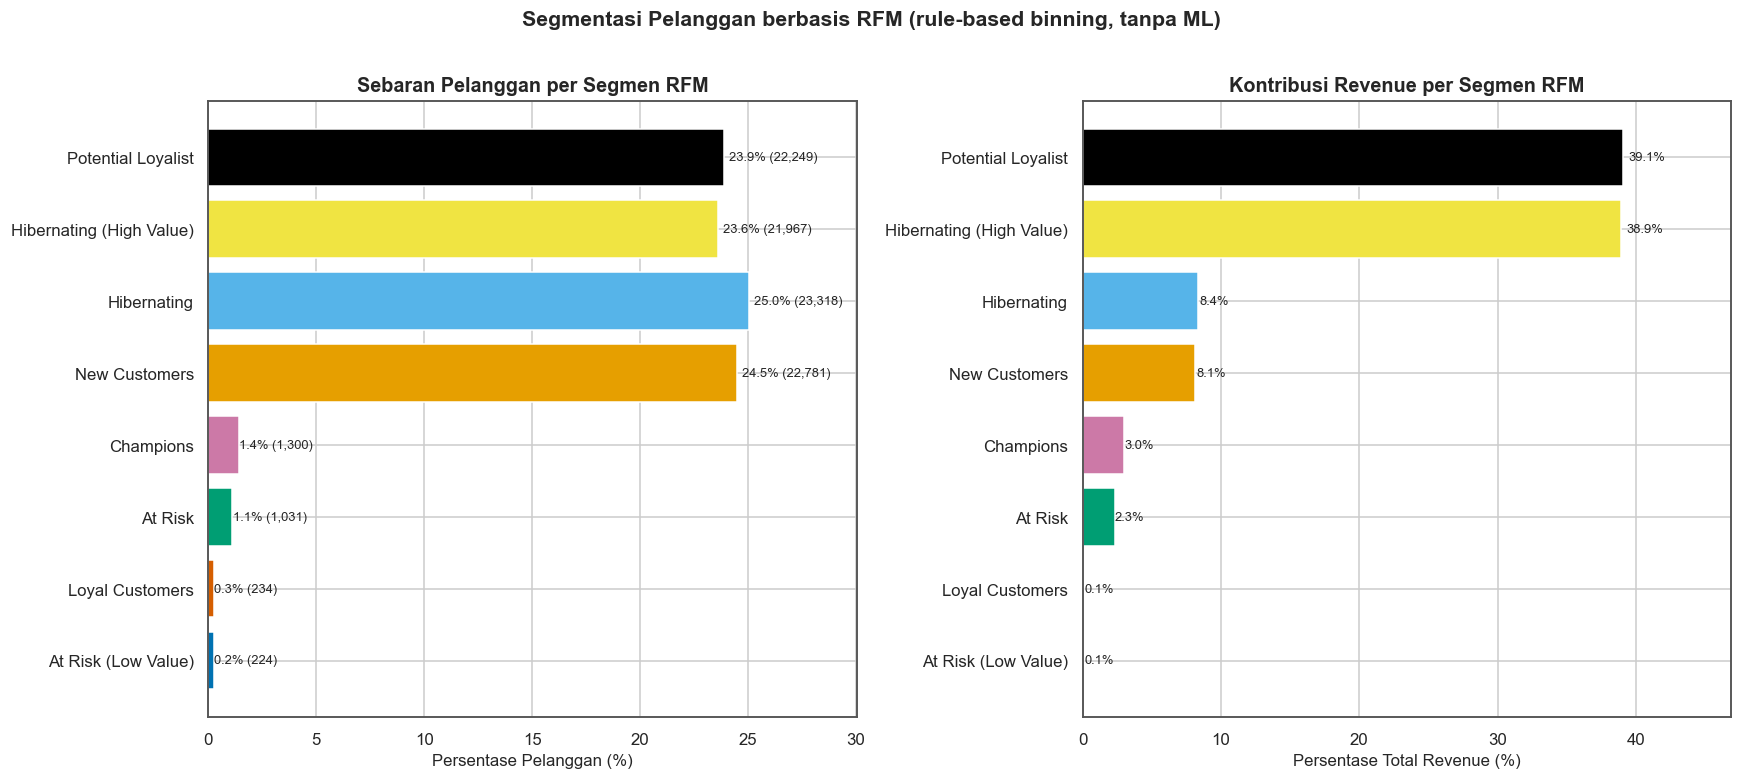

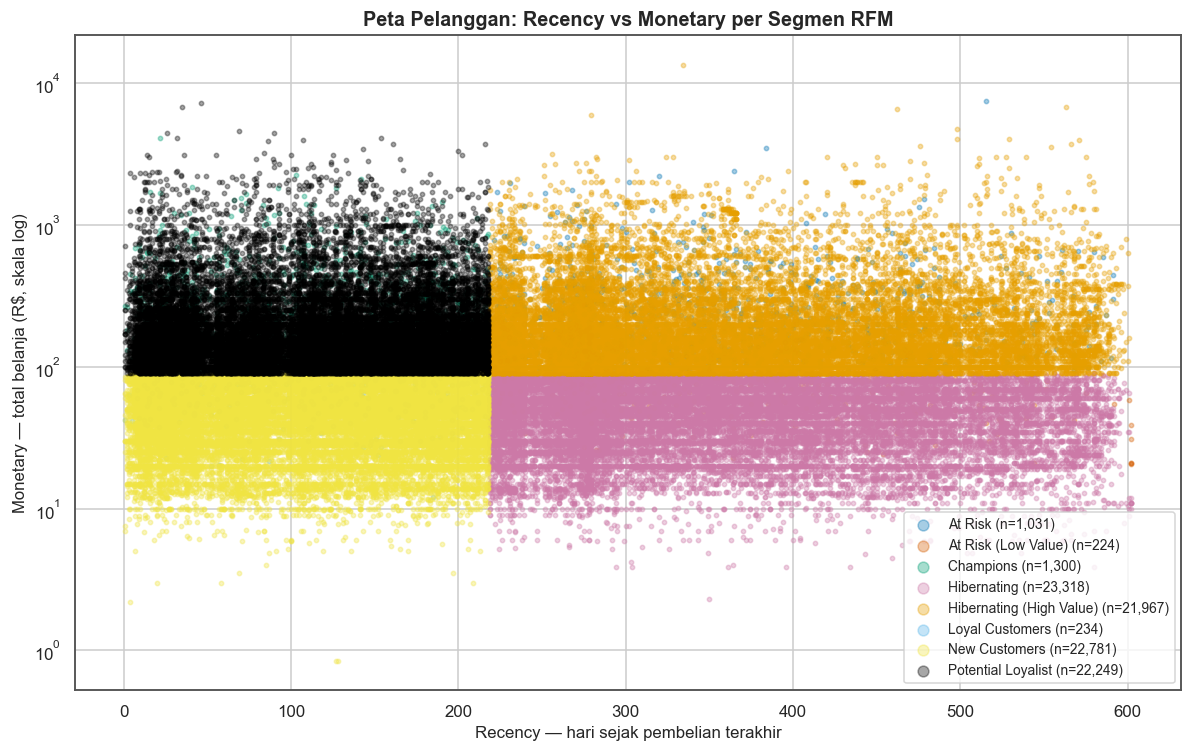

In [12]:
# --- Visualisasi hasil RFM ---
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

seg_sorted = seg.sort_values("pct_revenue", ascending=True)
colors = [PALETTE[i % len(PALETTE)] for i in range(len(seg_sorted))]

b1 = axes[0].barh(seg_sorted.index, seg_sorted.pct_pelanggan, color=colors, edgecolor="white")
axes[0].set_xlim(0, seg_sorted.pct_pelanggan.max() * 1.2)
axes[0].set_xlabel("Persentase Pelanggan (%)")
axes[0].set_title("Sebaran Pelanggan per Segmen RFM")
for b, v, n in zip(b1, seg_sorted.pct_pelanggan, seg_sorted.jumlah_pelanggan):
    axes[0].text(b.get_width() * 1.01, b.get_y() + b.get_height()/2,
                 f"{v:.1f}% ({n:,})", va="center", fontsize=8.5)

b2 = axes[1].barh(seg_sorted.index, seg_sorted.pct_revenue, color=colors, edgecolor="white")
axes[1].set_xlim(0, seg_sorted.pct_revenue.max() * 1.2)
axes[1].set_xlabel("Persentase Total Revenue (%)")
axes[1].set_title("Kontribusi Revenue per Segmen RFM")
for b, v in zip(b2, seg_sorted.pct_revenue):
    axes[1].text(b.get_width() * 1.01, b.get_y() + b.get_height()/2,
                 f"{v:.1f}%", va="center", fontsize=8.5)

fig.suptitle("Segmentasi Pelanggan berbasis RFM (rule-based binning, tanpa ML)",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Scatter: Recency vs Monetary, diwarnai per segmen
plt.figure(figsize=(11, 7))
for i, (name, grp) in enumerate(rfm.groupby("segment")):
    plt.scatter(grp.recency, grp.monetary, s=8, alpha=0.35,
                color=PALETTE[i % len(PALETTE)], label=f"{name} (n={len(grp):,})")
plt.yscale("log")                       # skala log karena monetary sangat right-skewed
plt.xlabel("Recency — hari sejak pembelian terakhir")
plt.ylabel("Monetary — total belanja (R$, skala log)")
plt.title("Peta Pelanggan: Recency vs Monetary per Segmen RFM")
plt.legend(markerscale=2.5, fontsize=9)
plt.tight_layout()
plt.show()

**Insight (Analisis Lanjutan — RFM):**

- **97,0% pelanggan (90.315 orang) hanya bertransaksi satu kali.** Hanya **3,0%**
  (2.789 orang) yang pernah *repeat order*. Ini temuan paling penting: **platform ini
  sangat bergantung pada akuisisi pelanggan baru dan hampir tidak punya retensi**.
- Meski jumlahnya kecil, pelanggan *repeat* rata-rata membelanjakan **R$ 260,08** —
  hampir **2× lipat** rata-rata pelanggan sekali beli (R$ 137,91). Artinya
  **meningkatkan retensi adalah peluang pendapatan dengan ROI tinggi**.
- Segmentasi menghasilkan **8 segmen dengan cakupan 100%** (tidak ada pelanggan yang
  tidak terklasifikasi). Dua segmen terbesar menyerap hampir seluruh revenue:
  **`Potential Loyalist`** (22.249 pelanggan; **39,09%** revenue) dan
  **`Hibernating (High Value)`** (21.967 pelanggan; **38,93%** revenue).
- **`Hibernating (High Value)`** adalah *hidden gem* bersejarah: pelanggan dengan
  belanja besar (rata-rata R$ 233,61) namun **sudah ~362 hari tidak bertransaksi**.
  Segmen ini adalah **target utama kampanye reaktivasi** (win-back) — nilainya besar
  namun berisiko hilang permanen.
- **`Champions`** hanya **1.300 pelanggan (1,40%)** tetapi menyumbang **2,97%** revenue
  dan rata-rata belanja tertinggi (R$ 300,86). Segmen ini perlu **program loyalty** khusus.
- **`At Risk`** (1.031 pelanggan; 2,32% revenue) sudah lama tidak aktif namun pernah
  aktif beberapa kali — prioritas kedua untuk kampanye win-back.

> **Catatan integritas:** pemotongan skor R dan M memakai **kuartil** (bukan rata-rata)
> karena distribusinya *skewed* — memakai rata-rata akan menempatkan hampir semua
> pelanggan pada satu kelas saja. `Frequency` memakai **bin manual** dengan alasan yang
> sama. Seluruh aturan bersifat **rule-based dan dapat direproduksi**, tanpa model
> machine learning.

### Export Data untuk Dashboard

Data bersih serta tabel RFM disimpan ke folder `dashboard/` agar **dashboard Streamlit
tidak perlu mengulang proses cleaning** dan cukup membaca CSV yang sudah siap pakai.

In [13]:
import os
os.makedirs("dashboard", exist_ok=True)

main_out = main_df[["order_id", "customer_unique_id", "order_purchase_timestamp", "order_month",
                    "order_status", "customer_state", "customer_city",
                    "product_category_name_english", "product_id", "price", "freight_value",
                    "payment_value", "payment_type", "review_score",
                    "delivery_days", "delay_days"]].copy()
main_out["order_purchase_timestamp"] = main_out["order_purchase_timestamp"].astype(str)
main_out.to_csv("dashboard/main_data.csv", index=False)
print(f"dashboard/main_data.csv -> {main_out.shape[0]:,} baris x {main_out.shape[1]} kolom")

rfm_out = rfm[["customer_unique_id", "recency", "frequency", "monetary", "R", "F", "M", "segment"]]
rfm_out.to_csv("dashboard/rfm_data.csv", index=False)
print(f"dashboard/rfm_data.csv  -> {rfm_out.shape[0]:,} baris x {rfm_out.shape[1]} kolom")

dashboard/main_data.csv -> 109,880 baris x 16 kolom
dashboard/rfm_data.csv  -> 93,104 baris x 8 kolom


## Conclusion & Recommendation

### Conclusion

**Pertanyaan 1 — Kategori produk dengan revenue tertinggi & terendah**

Kategori dengan total pendapatan tertinggi adalah **`health_beauty`**
(R$ 1.229.557,50; **9,45%**), disusul `watches_gifts` (8,94%), `bed_bath_table` (7,86%),
`sports_leisure` (7,32%), dan `computers_accessories` (6,83%). **Lima kategori teratas
menyumbang 40,4% dari total pendapatan.** Sebaliknya, kategori terendah adalah
**`security_and_services`** (R$ 283,29), diikuti `fashion_childrens_clothes`,
`cds_dvds_musicals`, `home_comfort_2`, dan `flowers` — kelimanya hanya **0,026%** dari
total pendapatan. Pendapatan platform **cukup terkonsentrasi** pada segelintir kategori.

**Pertanyaan 2 — Tren pesanan & pendapatan bulanan**

Pendapatan tumbuh dari R$ 111.798 (Jan 2017) ke puncak **R$ 987.765 pada November 2017**
(kenaikan **~7,5×**, dipicu **Black Friday**), lalu turun **26,50% pada Desember 2017**.
Sepanjang 2018, tren **melandai dan cenderung datar** di kisaran R$ 826.437 – 977.545
per bulan — pertumbuhan eksponensial 2017 **tidak berlanjut**, menandakan pasar mulai
*jenuh/mature* dan pertumbuhan berikutnya harus datang dari retensi atau kategori baru.

**Pertanyaan 3 — Sebaran geografis**

Pasar **sangat terkonsentrasi di São Paulo (SP)**: **R$ 5.055.587,13 (38,36%)** dari
total pendapatan dengan 40.406 pesanan. **Lima state teratas (SP, RJ, MG, RS, PR)
menyumbang 73,94%** pendapatan. Pelanggan tersebar di 4.083 kota, tetapi wilayah
Utara/Timur Laut berkontribusi kecil **dan** pengirimannya paling lambat (RR 28,3 hari)
dibanding SP (8,2 hari).

**Temuan lintas-pertanyaan (RFM):** **97,0% pelanggan hanya bertransaksi satu kali** —
masalah retensi terbesar platform, sekaligus peluang pendapatan terbesar karena
pelanggan *repeat* rata-rata membelanjakan ~2× lebih besar.

### Recommendation

Berdasarkan temuan di atas, ada **action items** yang dapat dijalankan:

1. **Prioritaskan kategori penyumbang utama (`health_beauty`, `watches_gifts`,
   `bed_bath_table`)** untuk alokasi stok, kerja sama *seller*, dan anggaran promosi —
   karena 5 kategori ini menyumbang 40,4% pendapatan. Evaluasi kategori dengan
   pendapatan < 0,01% (`security_and_services`, dll.) apakah layak diteruskan.
2. **Bangun program retensi & reaktivasi pelanggan** (ini prioritas #1 strategis):
   - Segmen **`Hibernating (High Value)`** (21.967 pelanggan; 38,93% revenue; idle
     ~362 hari) → kirim **kampanye win-back** bertarget (voucher/diskon personal).
   - Segmen **`Champions`** (1.300 pelanggan) → beri **program loyalty / early access**.
   - Pertimbangkan **win-back untuk `At Risk`** (1.031 pelanggan, pernah repeat).
3. **Antisipasi puncak musiman akhir tahun.** Lonjakan November (Black Friday,
   +52,37% MoM) harus disiapkan dengan **kapasitas logistik dan stok tambahan** sejak
   Oktober, agar tidak berujung keterlambatan yang menurunkan review.
4. **Perbaiki ketepatan waktu pengiriman sebagai prioritas layanan.** Pesanan terlambat
   mendapat review **2,257** vs **4,211** untuk tepat waktu (selisih 1,95 poin). Karena
   hanya **6,79% pesanan** yang terlambat, **perbaikan pada kelompok kecil ini berdampak
   langsung dan besar pada skor kepuasan keseluruhan** — *quick win* dengan upaya terbatas.
5. **Pertimbangkan gudang/pusat distribusi tambahan di luar São Paulo** untuk memangkas
   waktu kirim ke wilayah Timur Laut & Utara (RR 28,3 hari, AP 27,8 hari). Ini sekaligus
   membuka pasar yang saat ini kontribusinya kecil hanya karena kendala logistik.
6. **Lengkapi data kategori produk** di sistem katalog — masih ada **R$ 170.660,74**
   pendapatan yang tidak dapat diatribusikan ke kategori apa pun (`unknown`).
7. **Perluas analisis ke depan**: karena analisis ini *rule-based*, langkah berikutnya
   dapat menambahkan **uji A/B pada kampanye win-back** dan **analisis cohort retensi
   bulanan** untuk mengukur efektivitas program retensi secara kuantitatif.

---
### Ringkasan Teknik Analisis

| Tahap | Teknik yang digunakan |
|---|---|
| Data Wrangling | Pengecekan *missing value*, *duplicate*, *invalid/inconsistent value*, *outlier* (metode IQR), penggabungan antar tabel (*inner/left join*), agregasi pembayaran |
| EDA | Analisis *univariate* (histogram, statistik deskriptif), *bivariate* (rata-rata bersyarat), *multivariate* (matriks korelasi) |
| Visualisasi | Diagram batang terurut, *line chart* tren bulanan, *heatmap* korelasi, peta geografis interaktif (folium), *scatter plot* berskala log |
| Analisis Lanjutan | **RFM Analysis** dengan *scoring* berbasis **kuartil** (R, M) dan **binning manual** (F), dilanjutkan **segmentasi rule-based** 8 segmen (cakupan 100%) — **tanpa machine learning** |